In [9]:
import pandas as pd
from scipy.ndimage import median_filter as md

df = pd.read_csv("docs/design/data/belhaven-nc.csv", skiprows=[1], parse_dates=["time"])

water_level = df["water_surface_above_navd88"].to_numpy()        # metres, NAVD88
time = df["time"].dt.tz_convert("UTC").dt.tz_localize(None)      # pandas Series, tz-naive UTC
existing_qc = df["water_surface_above_navd88_qc_agg"].to_numpy() # aggregate QARTOD flags (1/3/4)
water_level2=md(water_level, size=3)


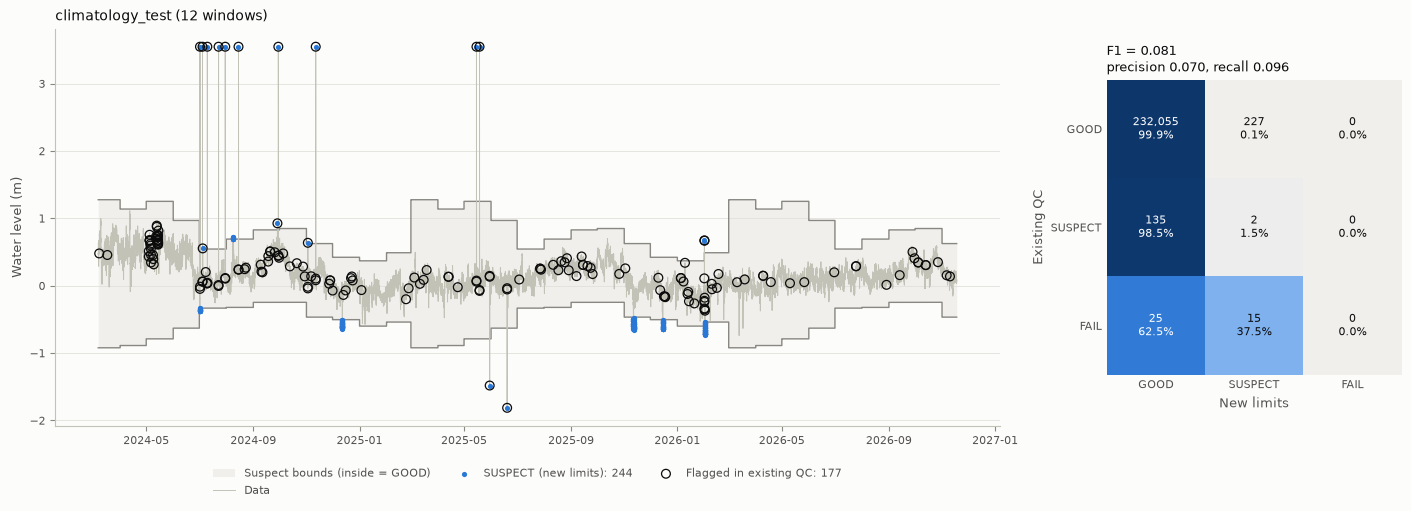

In [11]:
from ioos_qc import qartod
from ioos_qc.build_limits import auto_thresh, climatology_config, compare_flags, find_regimes, plot_limits

# Gross range: suspect from the data, fail from the manufacturer/experts
suspect = auto_thresh(water_level, n_std=3)
flags = qartod.gross_range_test(water_level, fail_span=(-3.0, 4.0), suspect_span=suspect)

# What regimes are in the record?
# find_regimes(water_level, time, method="segments", n_regimes=14)
find_regimes(water_level2, time, method="seasonal", period="month")

# Climatology config from those regimes
# cfg = climatology_config(water_level, time, method="segments", n_regimes=8, n_std=4,
#                          fail_span=(-3.0, 4.0))
cfg = climatology_config(water_level2, time, method="seasonal", period="month", n_std = 4, n_regimes=366)
flags = qartod.climatology_test(cfg, water_level, time)

# Compare with existing QC and plot
compare_flags(existing_qc, flags)["f1"]
fig = plot_limits(water_level, time, cfg, reference=existing_qc, ylabel="Water level (m)")


In [12]:
cfg

[{'tspan': (1, 1),
  'period': 'month',
  'vspan': (-0.5998399865663055, 0.3692714391522203)},
 {'tspan': (2, 2),
  'period': 'month',
  'vspan': (-0.5396464128588888, 0.48938550869975683)},
 {'tspan': (3, 3),
  'period': 'month',
  'vspan': (-0.9215218276837475, 1.276449511392127)},
 {'tspan': (4, 4),
  'period': 'month',
  'vspan': (-0.888006470748394, 1.1377906817127132)},
 {'tspan': (5, 5),
  'period': 'month',
  'vspan': (-0.7889670376004921, 1.2523374555747497)},
 {'tspan': (6, 6),
  'period': 'month',
  'vspan': (-0.630080345765957, 0.9688001578414989)},
 {'tspan': (7, 7),
  'period': 'month',
  'vspan': (-0.33294395139384747, 0.544120284772159)},
 {'tspan': (8, 8),
  'period': 'month',
  'vspan': (-0.32202200438463036, 0.6919223010963768)},
 {'tspan': (9, 9),
  'period': 'month',
  'vspan': (-0.24731102989133752, 0.8283866034935032)},
 {'tspan': (10, 10),
  'period': 'month',
  'vspan': (-0.24654311539582502, 0.8489453495594936)},
 {'tspan': (11, 11),
  'period': 'month',
  'vs